## 0. Configuração do Ambiente e Diretório de Trabalho (Google Drive)

Para garantir a persistência dos arquivos intermediários (`data/processed/`) e dos entregáveis (`outputs/`) entre todos os notebooks do pipeline (`01` a `06`) sem necessidade de reenvio manual a cada sessão do Google Colab, montamos o Google Drive e definimos a pasta raiz do projeto (`ifood-growth-competition-case`) como diretório ativo.

> **Nota de reprodutibilidade:** Caso execute este notebook localmente (VS Code / Jupyter), esta célula identifica automaticamente o ambiente local e mantém o diretório raiz do repositório sem exigir montagem do Google Drive.

In [1]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ifood-growth-competition-case'
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)
    print("Ambiente Google Colab conectado ao Drive:", os.getcwd())
except ImportError:
    # Execução local (VS Code / Jupyter / Terminal)
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    print("Ambiente local detectado:", os.getcwd())

Mounted at /content/drive
Ambiente Google Colab conectado ao Drive: /content/drive/MyDrive/ifood-growth-competition-case


# 01 — Análise Exploratória de Dados (EDA) e Validação da Base Real

**Objetivo:** Realizar a leitura, saneamento de formatos brasileiros (`R$`, `.` como milhar, `,` como decimal e `%`), validação de integridade e análise exploratória da base real **`Case_Competição_prático - Dados.csv`**.

**Regra de governança:** Nenhuma métrica será criada sem origem explícita na base real ou classificação transparente como premissa explícita na etapa de modelagem.


In [2]:
import os
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Localiza automaticamente o arquivo real
candidates = [
    "data/raw/Case_Competição_prático - Dados.csv",
    "../data/raw/Case_Competição_prático - Dados.csv",
    "/content/Case_Competição_prático - Dados.csv",
    "Case_Competição_prático - Dados.csv",
]

RAW_PATH = next((p for p in candidates if os.path.exists(p)), "/content/Case_Competição_prático - Dados.csv")
if RAW_PATH.startswith("../"):
    BASE_DIR = ".."
elif RAW_PATH.startswith("/content/"):
    BASE_DIR = "/content"
else:
    BASE_DIR = "."

PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed")
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")
REPORTS_DIR = os.path.join(BASE_DIR, "outputs", "reports")

for folder in [PROCESSED_DIR, FIGURES_DIR, REPORTS_DIR]:
    os.makedirs(folder, exist_ok=True)

print("RAW_PATH:", RAW_PATH)
print("PROCESSED_DIR:", PROCESSED_DIR)


RAW_PATH: Case_Competição_prático - Dados.csv
PROCESSED_DIR: ./data/processed


## 1. Carregamento e Inspeção Bruta


In [3]:
df_raw = pd.read_csv(RAW_PATH)
print("Shape original:", df_raw.shape)
print("Colunas originais:", list(df_raw.columns))
display(df_raw.head(20))


Shape original: (20, 15)
Colunas originais: ['Cidade', 'Orders', 'GMV', 'AOV', 'AOV Basket', 'Saturação', 'Ocupação', 'Entregadores', 'Margem de Contribuição', 'Operating Margin', 'Market Share', 'Custo/Hora Incremental', 'Custo/Pedido incremental', 'Frete Gratis (%)', 'Price Index']


,Cidade,Orders,GMV,AOV,AOV Basket,Saturação,Ocupação,Entregadores,Margem de Contribuição,Operating Margin,Market Share,Custo/Hora Incremental,Custo/Pedido incremental,Frete Gratis (%),Price Index
0,City 1,"329.465,76",R$22.126.920,R$67,R$58,"71,38%","50,19%",1076,"8,16%","-0,01%","93,00%","6,0","8,0",56%,"91,07%"
1,City 10,"47.493,57",R$3.343.072,R$70,R$60,"168,30%","56,53%",58,"7,49%","-3,58%","83,00%","9,0","5,0",38%,"97,68%"
2,City 11,"258.969,66",R$16.457.522,R$64,R$57,"147,87%","63,27%",324,"7,78%","6,21%","73,00%","9,0","5,0",49%,"113,08%"
3,City 12,"175.600,89",R$11.507.126,R$66,R$56,"87,94%","61,73%",378,"8,66%","1,88%","93,00%","10,0","8,0",44%,"94,74%"
4,City 13,"316.311,15",R$21.844.448,R$69,R$60,"70,38%","53,76%",978,"8,72%","2,84%","86,00%","14,0","4,0",41%,"101,32%"
5,City 14,"45.408,99",R$3.442.456,R$76,R$65,"96,14%","62,83%",88,"8,48%","0,89%","95,00%","15,0","7,0",48%,"94,85%"
6,City 15,"562.253,85",R$39.211.583,R$70,R$62,"86,18%","56,72%",1346,"7,29%","0,07%","91,00%","11,0","7,0",29%,"95,50%"
7,City 16,"308.942,97",R$21.953.487,R$71,R$61,"82,17%","46,77%",941,"7,53%","1,62%","86,00%","15,0","6,0",20%,"93,75%"
8,City 17,"2.003.389,05",R$162.615.089,R$81,R$73,"131,38%","57,83%",3085,"7,38%","-1,34%","67,00%","9,0","8,0",54%,"108,99%"
9,City 18,"630.705,33",R$41.916.676,R$66,R$59,"78,48%","45,01%",2089,"7,72%","-4,69%","65,00%","5,0","7,0",54%,"93,49%"


## 2. Padronização de Nomes e Conversão Numérica no Padrão Brasileiro (PT-BR)

Na base real **`Case_Competição_prático - Dados.csv`**:
- Valores monetários vêm formatados como `R$635.776.558` (ponto como separador de milhar, em reais absolutos).
- Pedidos (`Orders`) e percentuais vêm no formato brasileiro: `7.443.818,73` e `141,21%` (ponto como milhar, vírgula como decimal).
- Por isso, **removemos `.` (milhar) e substituímos `,` por `.` (decimal)** antes de converter para `float`, e criamos as escalas canônicas em **Milhões (`_m`)** e **Milhares (`_k`)** para consistência total com os notebooks seguintes.


In [4]:
def normalize_column(name: str) -> str:
    text = unicodedata.normalize("NFKD", str(name)).encode("ASCII", "ignore").decode("utf-8")
    text = (
        text.strip()
        .lower()
        .replace(" ", "_")
        .replace("/", "_")
        .replace("-", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("%", "pct")
    )
    while "__" in text:
        text = text.replace("__", "_")
    return text.strip("_")

def parse_ptbr_number(series: pd.Series) -> pd.Series:
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(series, errors="coerce")
    cleaned = (
        series.astype(str)
        .str.replace("R$", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.replace(".", "", regex=False)   # remove separador de milhar
        .str.replace(",", ".", regex=False)  # converte decimal PT-BR para ponto
        .str.strip()
    )
    return pd.to_numeric(cleaned, errors="coerce")

df = df_raw.copy()
df.columns = [normalize_column(c) for c in df.columns]
df = df.loc[:, ~df.columns.duplicated()].copy()

df["cidade"] = df["cidade"].astype(str).str.strip()
numeric_raw_cols = [c for c in df.columns if c != "cidade"]

for col in numeric_raw_cols:
    df[col] = parse_ptbr_number(df[col])

# Criação das colunas canônicas na escala do pipeline (Milhões e Milhares)
df["pedidos_base_k"] = df["orders"] / 1_000.0
df["gmv_base_m"] = df["gmv"] / 1_000_000.0
df["margem_contribuicao_pct"] = df["margem_de_contribuicao"]
df["margem_base_pct"] = df["operating_margin"]
df["margem_contribuicao_m"] = df["gmv_base_m"] * (df["margem_contribuicao_pct"] / 100.0)
df["margem_base_m"] = df["gmv_base_m"] * (df["margem_base_pct"] / 100.0)
df["saturacao_pct"] = df["saturacao"]
df["ocupacao_pct"] = df["ocupacao"]
df["share_pct"] = df["market_share"]
df["frete_gratis_pct"] = df["frete_gratis_pct"]
df["price_index_pct"] = df["price_index"]

print("Tipos após conversão:")
print(df.dtypes)
display(df.sort_values("gmv_base_m", ascending=False))


Tipos após conversão:
cidade                       object
orders                      float64
gmv                           int64
aov                           int64
aov_basket                    int64
saturacao                   float64
ocupacao                    float64
entregadores                  int64
margem_de_contribuicao      float64
operating_margin            float64
market_share                float64
custo_hora_incremental      float64
custo_pedido_incremental    float64
frete_gratis_pct              int64
price_index                 float64
pedidos_base_k              float64
gmv_base_m                  float64
margem_contribuicao_pct     float64
margem_base_pct             float64
margem_contribuicao_m       float64
margem_base_m               float64
saturacao_pct               float64
ocupacao_pct                float64
share_pct                   float64
price_index_pct             float64
dtype: object


,cidade,orders,gmv,aov,aov_basket,saturacao,ocupacao,entregadores,margem_de_contribuicao,operating_margin,market_share,custo_hora_incremental,custo_pedido_incremental,frete_gratis_pct,price_index,pedidos_base_k,gmv_base_m,margem_contribuicao_pct,margem_base_pct,margem_contribuicao_m,margem_base_m,saturacao_pct,ocupacao_pct,share_pct,price_index_pct
12,City 20,"7,443,818.7300",635776558,85,78,141.2100,47.5400,12974,8.0300,4.7800,74.0000,13.0000,8.0000,46,114.4400,"7,443.8187",635.7766,8.0300,4.7800,51.0529,30.3901,141.2100,47.5400,74.0000,114.4400
8,City 17,"2,003,389.0500",162615089,81,73,131.3800,57.8300,3085,7.3800,-1.3400,67.0000,9.0000,8.0000,54,108.9900,"2,003.3890",162.6151,7.3800,-1.3400,12.0010,-2.1790,131.3800,57.8300,67.0000,108.9900
13,City 3,"1,318,842.0600",101207940,77,69,79.8100,40.7100,4749,8.2200,6.0600,76.0000,6.0000,7.0000,27,101.2700,"1,318.8421",101.2079,8.2200,6.0600,8.3193,6.1332,79.8100,40.7100,76.0000,101.2700
11,City 2,"1,213,681.7700",87773466,72,63,83.8600,60.1800,2814,8.9600,8.4100,67.0000,13.0000,5.0000,55,116.8400,"1,213.6818",87.7735,8.9600,8.4100,7.8645,7.3817,83.8600,60.1800,67.0000,116.8400
16,City 6,"893,992.8900",63312576,71,60,96.5000,65.8900,1645,7.8300,7.0900,68.0000,7.0000,8.0000,27,111.7300,893.9929,63.3126,7.8300,7.0900,4.9574,4.4889,96.5000,65.8900,68.0000,111.7300
19,City 9,"901,869.4500",60758945,67,60,165.2800,41.4900,1539,7.5000,5.9000,78.0000,10.0000,4.0000,25,104.9400,901.8694,60.7589,7.5000,5.9000,4.5569,3.5848,165.2800,41.4900,78.0000,104.9400
14,City 4,"793,354.7400",52163074,66,57,129.0500,54.5100,1319,7.7800,3.3900,73.0000,5.0000,4.0000,59,96.6100,793.3547,52.1631,7.7800,3.3900,4.0583,1.7683,129.0500,54.5100,73.0000,96.6100
9,City 18,"630,705.3300",41916676,66,59,78.4800,45.0100,2089,7.7200,-4.6900,65.0000,5.0000,7.0000,54,93.4900,630.7053,41.9167,7.7200,-4.6900,3.2360,-1.9659,78.4800,45.0100,65.0000,93.4900
6,City 15,"562,253.8500",39211583,70,62,86.1800,56.7200,1346,7.2900,0.0700,91.0000,11.0000,7.0000,29,95.5000,562.2538,39.2116,7.2900,0.0700,2.8585,0.0274,86.1800,56.7200,91.0000,95.5000
0,City 1,"329,465.7600",22126920,67,58,71.3800,50.1900,1076,8.1600,-0.0100,93.0000,6.0000,8.0000,56,91.0700,329.4658,22.1269,8.1600,-0.0100,1.8056,-0.0022,71.3800,50.1900,93.0000,91.0700


## 3. Auditoria de Integridade e Consistência


In [5]:
print("=== AUDITORIA DE INTEGRIDADE ===")
print("Total de registros:", len(df))
print("Cidades únicas:", df["cidade"].nunique())
print("Cidades duplicadas:", df["cidade"].duplicated().sum())
print("\nValores nulos por coluna:")
print(df.isnull().sum())

# Verifica consistência entre GMV, Orders e AOV
df["aov_calculado"] = df["gmv"] / df["orders"]
df["diff_aov"] = (df["aov_calculado"] - df["aov"]).abs()
print("\nDiferença máxima entre (GMV / Orders) e AOV informado (arredondado na base):", round(df["diff_aov"].max(), 2))


=== AUDITORIA DE INTEGRIDADE ===
Total de registros: 20
Cidades únicas: 20
Cidades duplicadas: 0

Valores nulos por coluna:
cidade                      0
orders                      0
gmv                         0
aov                         0
aov_basket                  0
saturacao                   0
ocupacao                    0
entregadores                0
margem_de_contribuicao      0
operating_margin            0
market_share                0
custo_hora_incremental      0
custo_pedido_incremental    0
frete_gratis_pct            0
price_index                 0
pedidos_base_k              0
gmv_base_m                  0
margem_contribuicao_pct     0
margem_base_pct             0
margem_contribuicao_m       0
margem_base_m               0
saturacao_pct               0
ocupacao_pct                0
share_pct                   0
price_index_pct             0
dtype: int64

Diferença máxima entre (GMV / Orders) e AOV informado (arredondado na base): 0.49


## 4. Estatísticas Descritivas e KPIs Consolidados


In [6]:
cols_desc = [
    "gmv_base_m", "pedidos_base_k", "aov", "aov_basket",
    "saturacao_pct", "ocupacao_pct", "entregadores",
    "margem_contribuicao_pct", "margem_base_pct", "margem_base_m",
    "share_pct", "custo_hora_incremental", "custo_pedido_incremental",
    "frete_gratis_pct", "price_index_pct"
]
display(df[cols_desc].describe().T)

gmv_total = df["gmv_base_m"].sum()
pedidos_total = df["pedidos_base_k"].sum()
margem_contrib_total = df["margem_contribuicao_m"].sum()
margem_op_total = df["margem_base_m"].sum()

summary_kpis = {
    "total_cidades": int(df["cidade"].nunique()),
    "gmv_base_total_m": round(float(gmv_total), 2),
    "pedidos_base_total_k": round(float(pedidos_total), 2),
    "ticket_medio_ponderado_rs": round(float((gmv_total * 1e6) / (pedidos_total * 1e3)), 2),
    "margem_contribuicao_total_m": round(float(margem_contrib_total), 2),
    "margem_contribuicao_ponderada_pct": round(float((margem_contrib_total / gmv_total) * 100.0), 2),
    "margem_base_total_m": round(float(margem_op_total), 2),
    "margem_base_ponderada_pct": round(float((margem_op_total / gmv_total) * 100.0), 2),
    "total_entregadores": int(df["entregadores"].sum()),
    "saturacao_media_pct": round(float(df["saturacao_pct"].mean()), 2),
    "ocupacao_media_pct": round(float(df["ocupacao_pct"].mean()), 2),
    "share_medio_pct": round(float(df["share_pct"].mean()), 2),
}

print("=== KPIs CONSOLIDADOS DA BASE REAL ===")
for k, v in summary_kpis.items():
    print(f"- {k}: {v}")


,count,mean,std,min,25%,50%,75%,max
gmv_base_m,20.0000,69.4341,139.2813,0.3563,15.2199,22.0402,61.3974,635.7766
pedidos_base_k,20.0000,892.2012,"1,626.0094",6.4436,238.1275,322.8885,895.9620,"7,443.8187"
aov,20.0000,70.6500,6.5637,55.0000,66.7500,70.0000,75.2500,85.0000
aov_basket,20.0000,62.2000,6.5180,49.0000,58.7500,60.5000,65.5000,78.0000
saturacao_pct,20.0000,106.3125,30.7906,70.3800,83.4375,96.3200,129.6325,168.3000
ocupacao_pct,20.0000,55.1475,8.3338,40.7100,48.0575,55.9050,62.0050,68.9600
entregadores,20.0000,"1,832.5500","2,885.0764",11.0000,364.5000,"1,027.0000","1,756.0000","12,974.0000"
margem_contribuicao_pct,20.0000,7.9675,0.5482,7.0700,7.5225,7.8650,8.2850,8.9600
margem_base_pct,20.0000,3.2790,4.0545,-4.6900,0.6850,3.1150,6.1725,11.2100
margem_base_m,20.0000,2.7678,6.9395,-2.1790,0.0226,0.4880,2.4655,30.3901


=== KPIs CONSOLIDADOS DA BASE REAL ===
- total_cidades: 20
- gmv_base_total_m: 1388.68
- pedidos_base_total_k: 17844.02
- ticket_medio_ponderado_rs: 77.82
- margem_contribuicao_total_m: 110.68
- margem_contribuicao_ponderada_pct: 7.97
- margem_base_total_m: 55.36
- margem_base_ponderada_pct: 3.99
- total_entregadores: 36651
- saturacao_media_pct: 106.31
- ocupacao_media_pct: 55.15
- share_medio_pct: 78.05


## 5. Análise de Concentração (Pareto de GMV) e Trade-off Operacional


,rank_gmv,cidade,gmv_base_m,gmv_share_pct,gmv_cum_pct,margem_contribuicao_pct,margem_base_pct,saturacao_pct,ocupacao_pct,share_pct,price_index_pct
0,1,City 20,635.7766,45.7827,45.7827,8.0300,4.7800,141.2100,47.5400,74.0000,114.4400
1,2,City 17,162.6151,11.7100,57.4928,7.3800,-1.3400,131.3800,57.8300,67.0000,108.9900
2,3,City 3,101.2079,7.2881,64.7808,8.2200,6.0600,79.8100,40.7100,76.0000,101.2700
3,4,City 2,87.7735,6.3206,71.1015,8.9600,8.4100,83.8600,60.1800,67.0000,116.8400
4,5,City 6,63.3126,4.5592,75.6606,7.8300,7.0900,96.5000,65.8900,68.0000,111.7300
5,6,City 9,60.7589,4.3753,80.0359,7.5000,5.9000,165.2800,41.4900,78.0000,104.9400
6,7,City 4,52.1631,3.7563,83.7922,7.7800,3.3900,129.0500,54.5100,73.0000,96.6100
7,8,City 18,41.9167,3.0185,86.8107,7.7200,-4.6900,78.4800,45.0100,65.0000,93.4900
8,9,City 15,39.2116,2.8237,89.6343,7.2900,0.0700,86.1800,56.7200,91.0000,95.5000
9,10,City 1,22.1269,1.5934,91.2277,8.1600,-0.0100,71.3800,50.1900,93.0000,91.0700


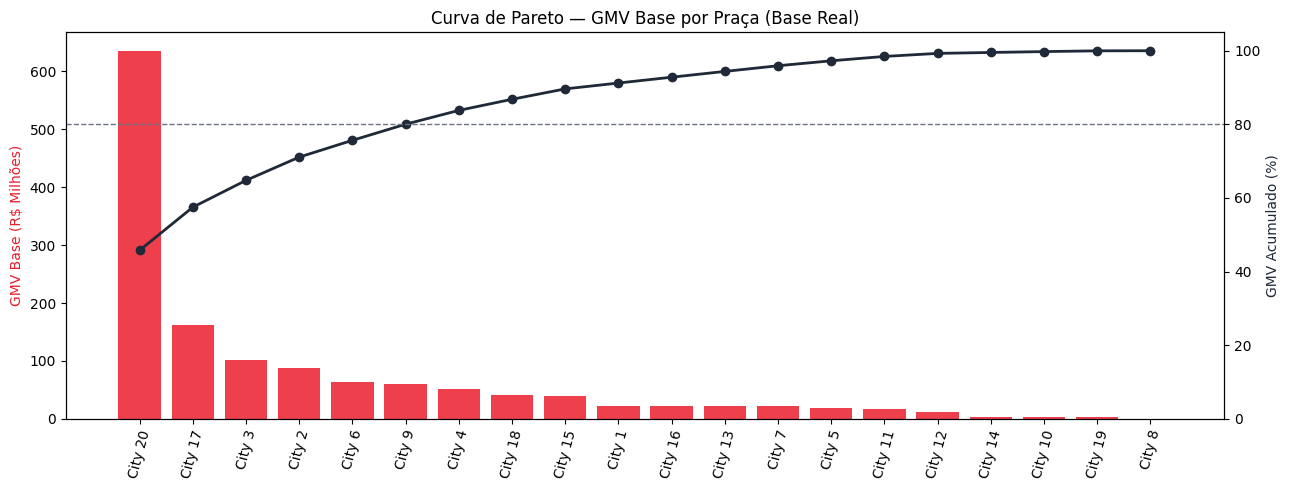

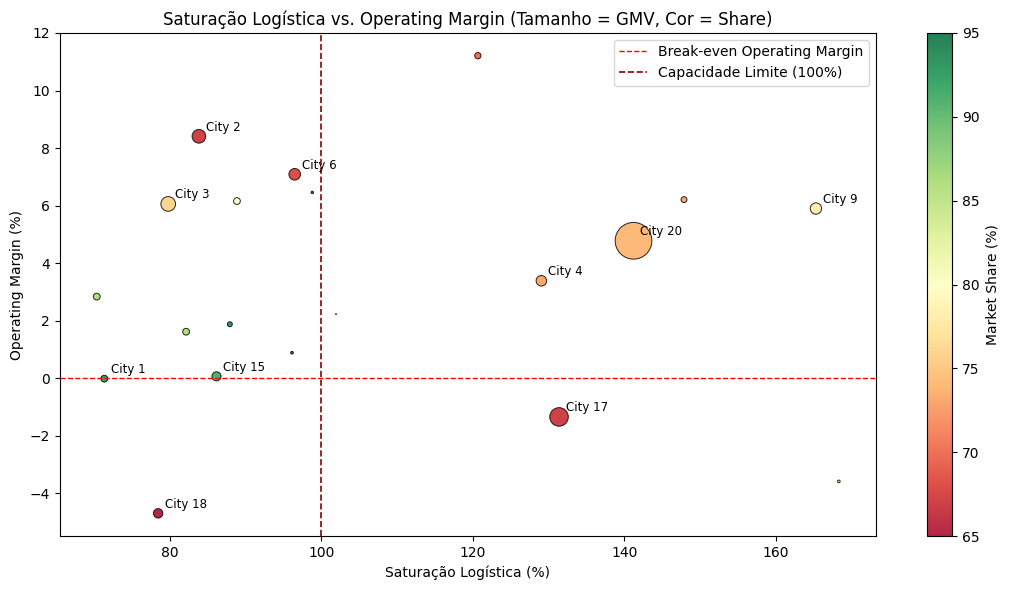

In [7]:
df_pareto = df.sort_values("gmv_base_m", ascending=False).reset_index(drop=True)
df_pareto["rank_gmv"] = df_pareto.index + 1
df_pareto["gmv_share_pct"] = (df_pareto["gmv_base_m"] / gmv_total) * 100.0
df_pareto["gmv_cum_pct"] = df_pareto["gmv_share_pct"].cumsum()

display(df_pareto[[
    "rank_gmv", "cidade", "gmv_base_m", "gmv_share_pct", "gmv_cum_pct",
    "margem_contribuicao_pct", "margem_base_pct", "saturacao_pct",
    "ocupacao_pct", "share_pct", "price_index_pct"
]])

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(df_pareto["cidade"], df_pareto["gmv_base_m"], color="#EA1D2C", alpha=0.85)
ax1.set_ylabel("GMV Base (R$ Milhões)", color="#EA1D2C")
ax1.tick_params(axis="x", rotation=75)

ax2 = ax1.twinx()
ax2.plot(df_pareto["cidade"], df_pareto["gmv_cum_pct"], color="#1F2937", marker="o", linewidth=2)
ax2.axhline(80, color="#6B7280", linestyle="--", linewidth=1, label="Corte 80% GMV")
ax2.set_ylabel("GMV Acumulado (%)", color="#1F2937")
ax2.set_ylim(0, 105)

plt.title("Curva de Pareto — GMV Base por Praça (Base Real)")
fig.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01_pareto_gmv.png"), dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
scatter = ax.scatter(
    df["saturacao_pct"],
    df["margem_base_pct"],
    s=df["gmv_base_m"] * 1.1,
    c=df["share_pct"],
    cmap="RdYlGn",
    alpha=0.85,
    edgecolors="black",
    linewidth=0.7
)
ax.axhline(0, color="red", linestyle="--", linewidth=1, label="Break-even Operating Margin")
ax.axvline(100, color="darkred", linestyle="--", linewidth=1.2, label="Capacidade Limite (100%)")
for _, r in df_pareto.head(10).iterrows():
    ax.annotate(r["cidade"], (r["saturacao_pct"], r["margem_base_pct"]), fontsize=8.5, xytext=(5, 4), textcoords="offset points")

cbar = plt.colorbar(scatter)
cbar.set_label("Market Share (%)")
ax.set_xlabel("Saturação Logística (%)")
ax.set_ylabel("Operating Margin (%)")
ax.set_title("Saturação Logística vs. Operating Margin (Tamanho = GMV, Cor = Share)")
ax.legend()
fig.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01b_saturacao_vs_margem.png"), dpi=150)
plt.show()


## 6. Exportação da Base Validada


In [8]:
cols_to_drop = [c for c in ["aov_calculado", "diff_aov"] if c in df.columns]
df_clean = df.drop(columns=cols_to_drop)

clean_csv_path = os.path.join(PROCESSED_DIR, "base_validada.csv")
df_clean.to_csv(clean_csv_path, index=False)

report_path = os.path.join(REPORTS_DIR, "eda_summary.json")
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(summary_kpis, f, ensure_ascii=False, indent=2)

print("Base validada salva em:", clean_csv_path)
print("Resumo KPIs salvo em:", report_path)


Base validada salva em: ./data/processed/base_validada.csv
Resumo KPIs salvo em: ./outputs/reports/eda_summary.json
